# Understanding vectorizers

A vectorizer turns texts into rows of numbers. This walkthrough explains
what those numbers mean and how to inspect them. Run the cells from top to bottom.

You can also try editing texts and comparing methods in the [interactive app](https://apps-computational-teaching-jj92xohbgnwnhksxlclr8t.streamlit.app/).

## First, watch the steps

This animation uses two headlines from the slides. `fit()` learns the
vocabulary; `transform()` counts those words in each text.

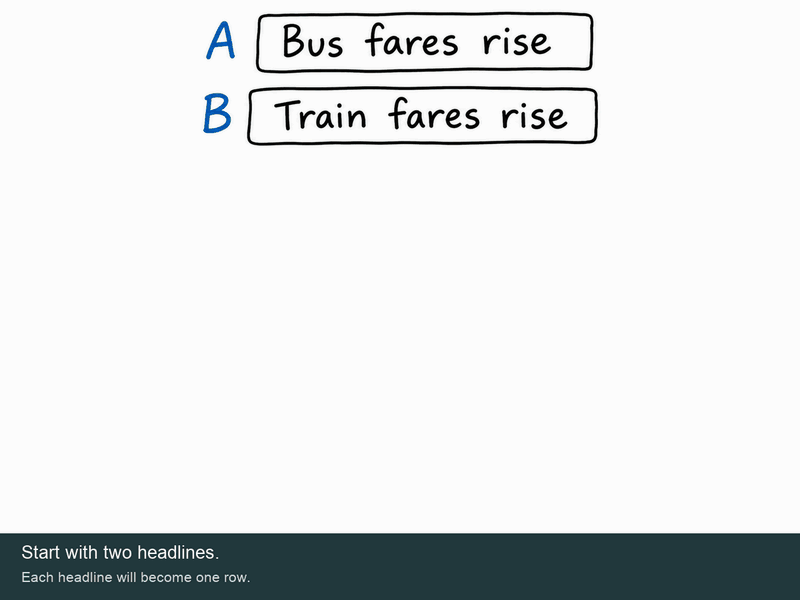

Below, we add two more headlines so we can compare counts and TF-IDF weights.

## 1. Count words

Run the next cells. If pandas or scikit-learn is missing, uncomment the
installation line and run it once.

In [2]:
# %pip install pandas scikit-learn

import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

In [4]:
texts = [
    "Bus fares rise",
    "Train fares rise",
    "Bus fares rise as train fares rise",
    "City plans new tram line",
]
labels = ["A", "B", "C", "D"]

`fit_transform()` does two things:

1. It learns which words occur in this collection and gives each a column.
2. It counts how often each word occurs in each text.

The vocabulary below follows the column order of the matrix.

In [13]:
cv = CountVectorizer()
dtm = cv.fit_transform(texts)

print("Vocabulary:", cv.get_feature_names_out())
print("Matrix shape:", dtm.shape)

Vocabulary: ['as' 'bus' 'city' 'fares' 'line' 'new' 'plans' 'rise' 'train' 'tram']
Matrix shape: (4, 10)


**Inspect the table below.** What do its rows, columns, and numbers represent?
Why is there a 2 in the “fares” column for text C?

`toarray()` makes the small matrix readable here. For a large collection of
texts, keep the sparse representation instead.

In [14]:
count_table = pd.DataFrame(
    dtm.toarray(),
    columns=cv.get_feature_names_out(),
    index=labels,
)
display(count_table)

,as,bus,city,fares,line,new,plans,rise,train,tram
A,0,1,0,1,0,0,0,1,0,0
B,0,0,0,1,0,0,0,1,1,0
C,1,1,0,2,0,0,0,2,1,0
D,0,0,1,0,1,1,1,0,0,1


**Answer:** each row is a headline; each column is a word in the vocabulary.
The numbers are word counts. Text C contains “fares” twice and “rise” twice.
A zero means the word does not occur in that headline.

There are four texts and ten distinct tokens, so the shape is `(4, 10)`.
By default, `CountVectorizer` lowercases the text and uses tokens of at least
two letters, digits, or underscores.

## 2. Read the sparse representation

For a large collection, most words will be absent from most texts.
**Dense storage** keeps every count, including the zeros. **Sparse storage**
keeps the non-zero counts and their positions; unlisted positions mean zero.

The animation uses the same four headlines as the table above. Follow the
first count from headline A to the list on the right.

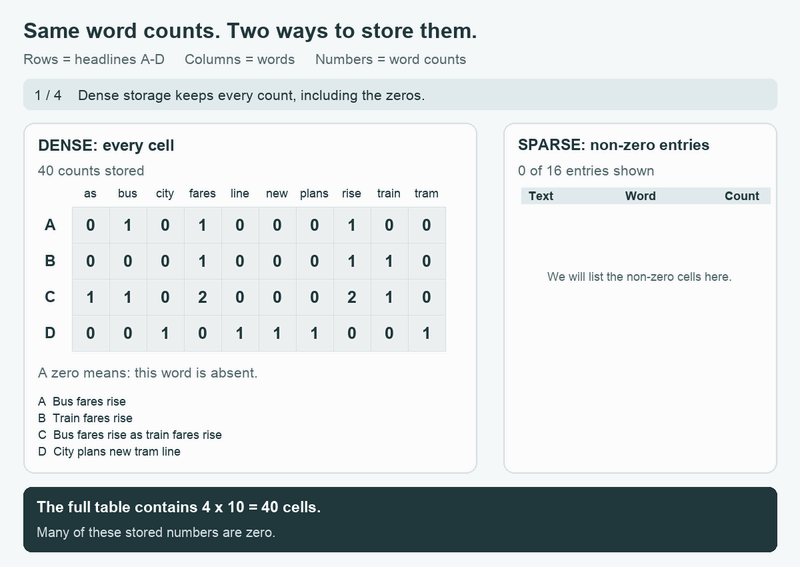

The list uses headline letters and words to make the positions easy to read.
It illustrates the idea; Python stores these positions as numbers and uses
a more compact internal layout. The matrix still has four rows and ten columns.
With large text collections, avoiding all those stored zeros can save a lot of memory.

Inspired by [Matt Eding's sparse-matrix visualisations](https://matteding.github.io/2019/04/25/sparse-matrices/),
using our own headlines and counts.

Run the next cell. It prints just the first row, for headline A.


In [7]:
print(dtm[0:1])

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 3 stored elements and shape (1, 10)>
  Coords	Values
  (0, 1)	1
  (0, 3)	1
  (0, 7)	1


**Answer:** the coordinates use positions starting at zero. For example,
`(0, 1) 1` means: row 0, column 1, count 1. Column 1 is “bus”.
The other two entries in this row are for “fares” and “rise”.
Words with a zero count are not listed.

The exact spacing and headings in this output can differ between package versions.

The dictionary below maps each word to its **column position**, not its count.
For example, `"bus": 1` identifies the “bus” column.

In [8]:
print(cv.vocabulary_)

{'bus': 1, 'fares': 3, 'rise': 7, 'train': 8, 'as': 0, 'city': 2, 'plans': 6, 'new': 5, 'tram': 9, 'line': 4}


### How many cells are zero?

Here, sparsity means the proportion of zero cells in the matrix.
Count the non-zero **cells**, rather than adding the word counts:
a cell containing 2 is still only one non-zero cell.

In [9]:
nonzero_cells = dtm.count_nonzero()
total_cells = dtm.shape[0] * dtm.shape[1]
sparsity = 1 - nonzero_cells / total_cells

print("Non-zero cells:", nonzero_cells)
print("Total cells:", total_cells)
print(f"Zero cells: {sparsity:.0%}")

Non-zero cells: 16
Total cells: 40
Zero cells: 60%


**Answer:** 16 of the 40 cells are non-zero. The remaining 24 cells are zero,
so sparsity is 60%. The word counts add up to 18, but that is a different
quantity: it counts word occurrences, including repetitions.

## 3. Compare counts with TF-IDF

TF-IDF starts from word frequency and gives less weight to words that appear
in more documents. The default vectorizer also normalises each row so that
document length does not simply determine the scale of the numbers.

Run the code and compare this table with the count table. Look at “bus” and
“fares” in headline A: both occur once, but do they receive the same weight?

In [10]:
tfidf_cv = TfidfVectorizer()
tfidf_matrix = tfidf_cv.fit_transform(texts)

tfidf_table = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf_cv.get_feature_names_out(),
    index=labels,
)
display(tfidf_table.round(3))

,as,bus,city,fares,line,new,plans,rise,train,tram
A,0.000,0.658,0.000,0.533,0.000,0.000,0.000,0.533,0.000,0.000
B,0.000,0.000,0.000,0.533,0.000,0.000,0.000,0.533,0.658,0.000
C,0.426,0.336,0.000,0.544,0.000,0.000,0.000,0.544,0.336,0.000
D,0.000,0.000,0.447,0.000,0.447,0.447,0.447,0.000,0.000,0.447


**Answer:** “bus” receives a higher weight than “fares” in headline A.
“Bus” occurs in two headlines, whereas “fares” occurs in three.
The IDF weighting therefore gives “bus” more weight when their counts are equal
in the same headline.

These are weights, not counts, probabilities, or percentages. With the default
normalisation, a row's values need not add up to 1.
TF-IDF does not determine which words matter for your research question or
understand their meaning. Whether it helps depends on the task.

## 4. Apply the same vocabulary to a new text

We have already fitted `cv`. Now use `transform()` to count words in a new
headline while keeping the same columns.

**Before running the code:** will “fall” appear as a new column?

In [15]:
new_texts = ["Bus fares fall"]
new_dtm = cv.transform(new_texts)

display(pd.DataFrame(
    new_dtm.toarray(),
    columns=cv.get_feature_names_out(),
    index=new_texts,
))

,as,bus,city,fares,line,new,plans,rise,train,tram
Bus fares fall,0,1,0,1,0,0,0,0,0,0


**Answer:** no. “Fall” was not in the vocabulary learned from the original
four headlines, so it is ignored. “Bus” and “fares” each receive a count of 1.
Using `transform()` keeps the columns consistent across texts.

Fitting a vectorizer again on the new text would learn a different vocabulary.

For reference:
[CountVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html)
and [TfidfVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html).